# Графики

In [1]:
%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_format = "retina"

from pathlib import Path

import numpy as np
import pandas as pd

import data_loading
import brands
import hypotheses as hyp
import pca_tsne as pca
import eda
import utils
import visualize

FIGURES = Path("figures")
FIGURES_MPL = FIGURES / "matplotlib"
FIGURES_PLOTLY = FIGURES / "plotly"
for folder in (FIGURES_MPL, FIGURES_PLOTLY):
    folder.mkdir(parents=True, exist_ok=True)

path = Path("../data/raw/vladimirskaia-oblast.geojson")
records = data_loading.load_records(path)

df = data_loading.record_to_full_frame(records)
participants = eda.participants_frame(df)
vehicles = eda.vehicle_frame(df)

len(df), len(participants), len(vehicles)
import matplotlib.pyplot as plt
import plotly.io as pio

plt.style.use("default")
pio.renderers.default = "plotly_mimetype"


## Временной ряд

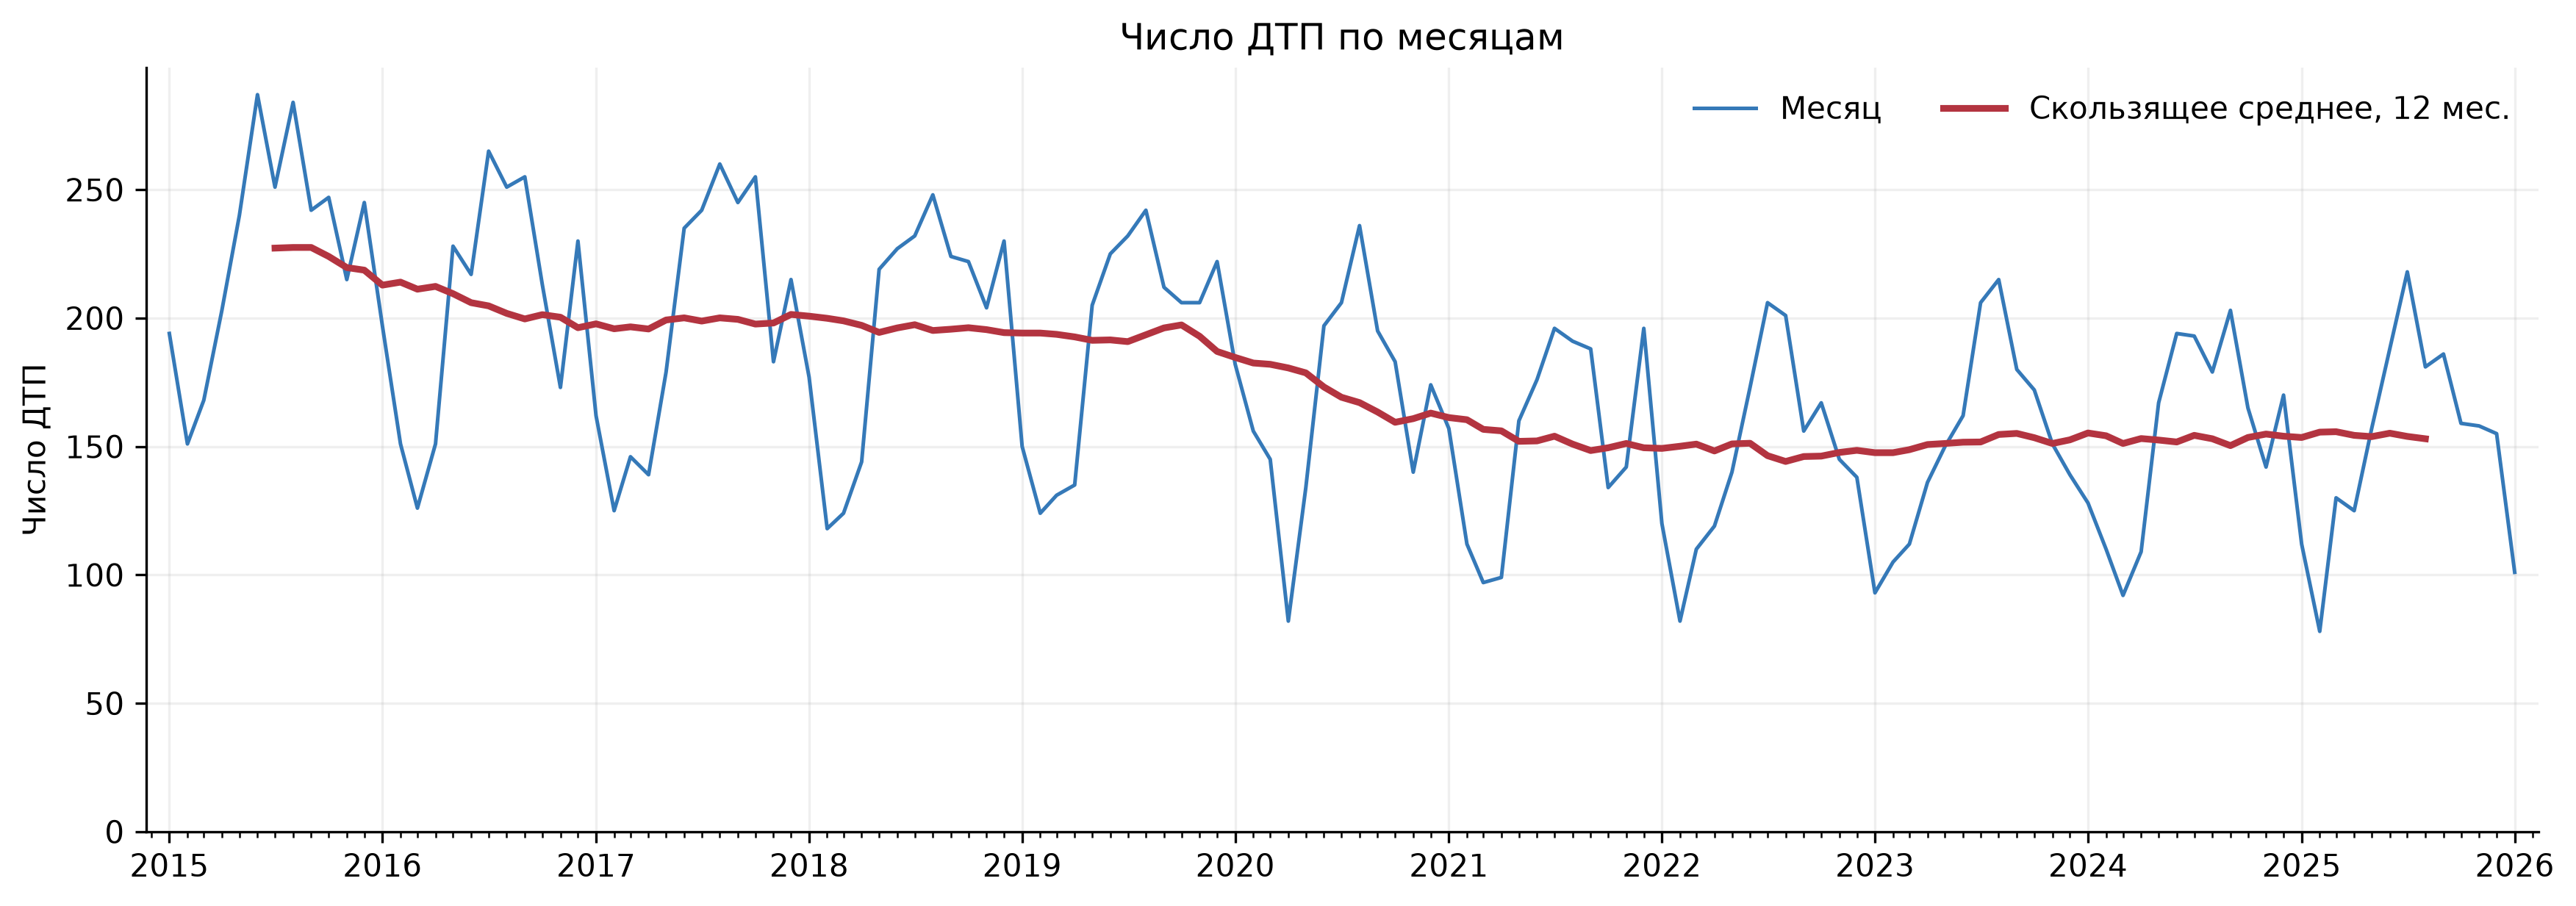

In [2]:
monthly = eda.dtp_year_month_frame(df)
fig, ax = visualize.accidents_by_month_line(monthly)
fig.savefig(FIGURES_MPL / "accidents_by_month.png", dpi=200, facecolor="white")

## Категории ДТП

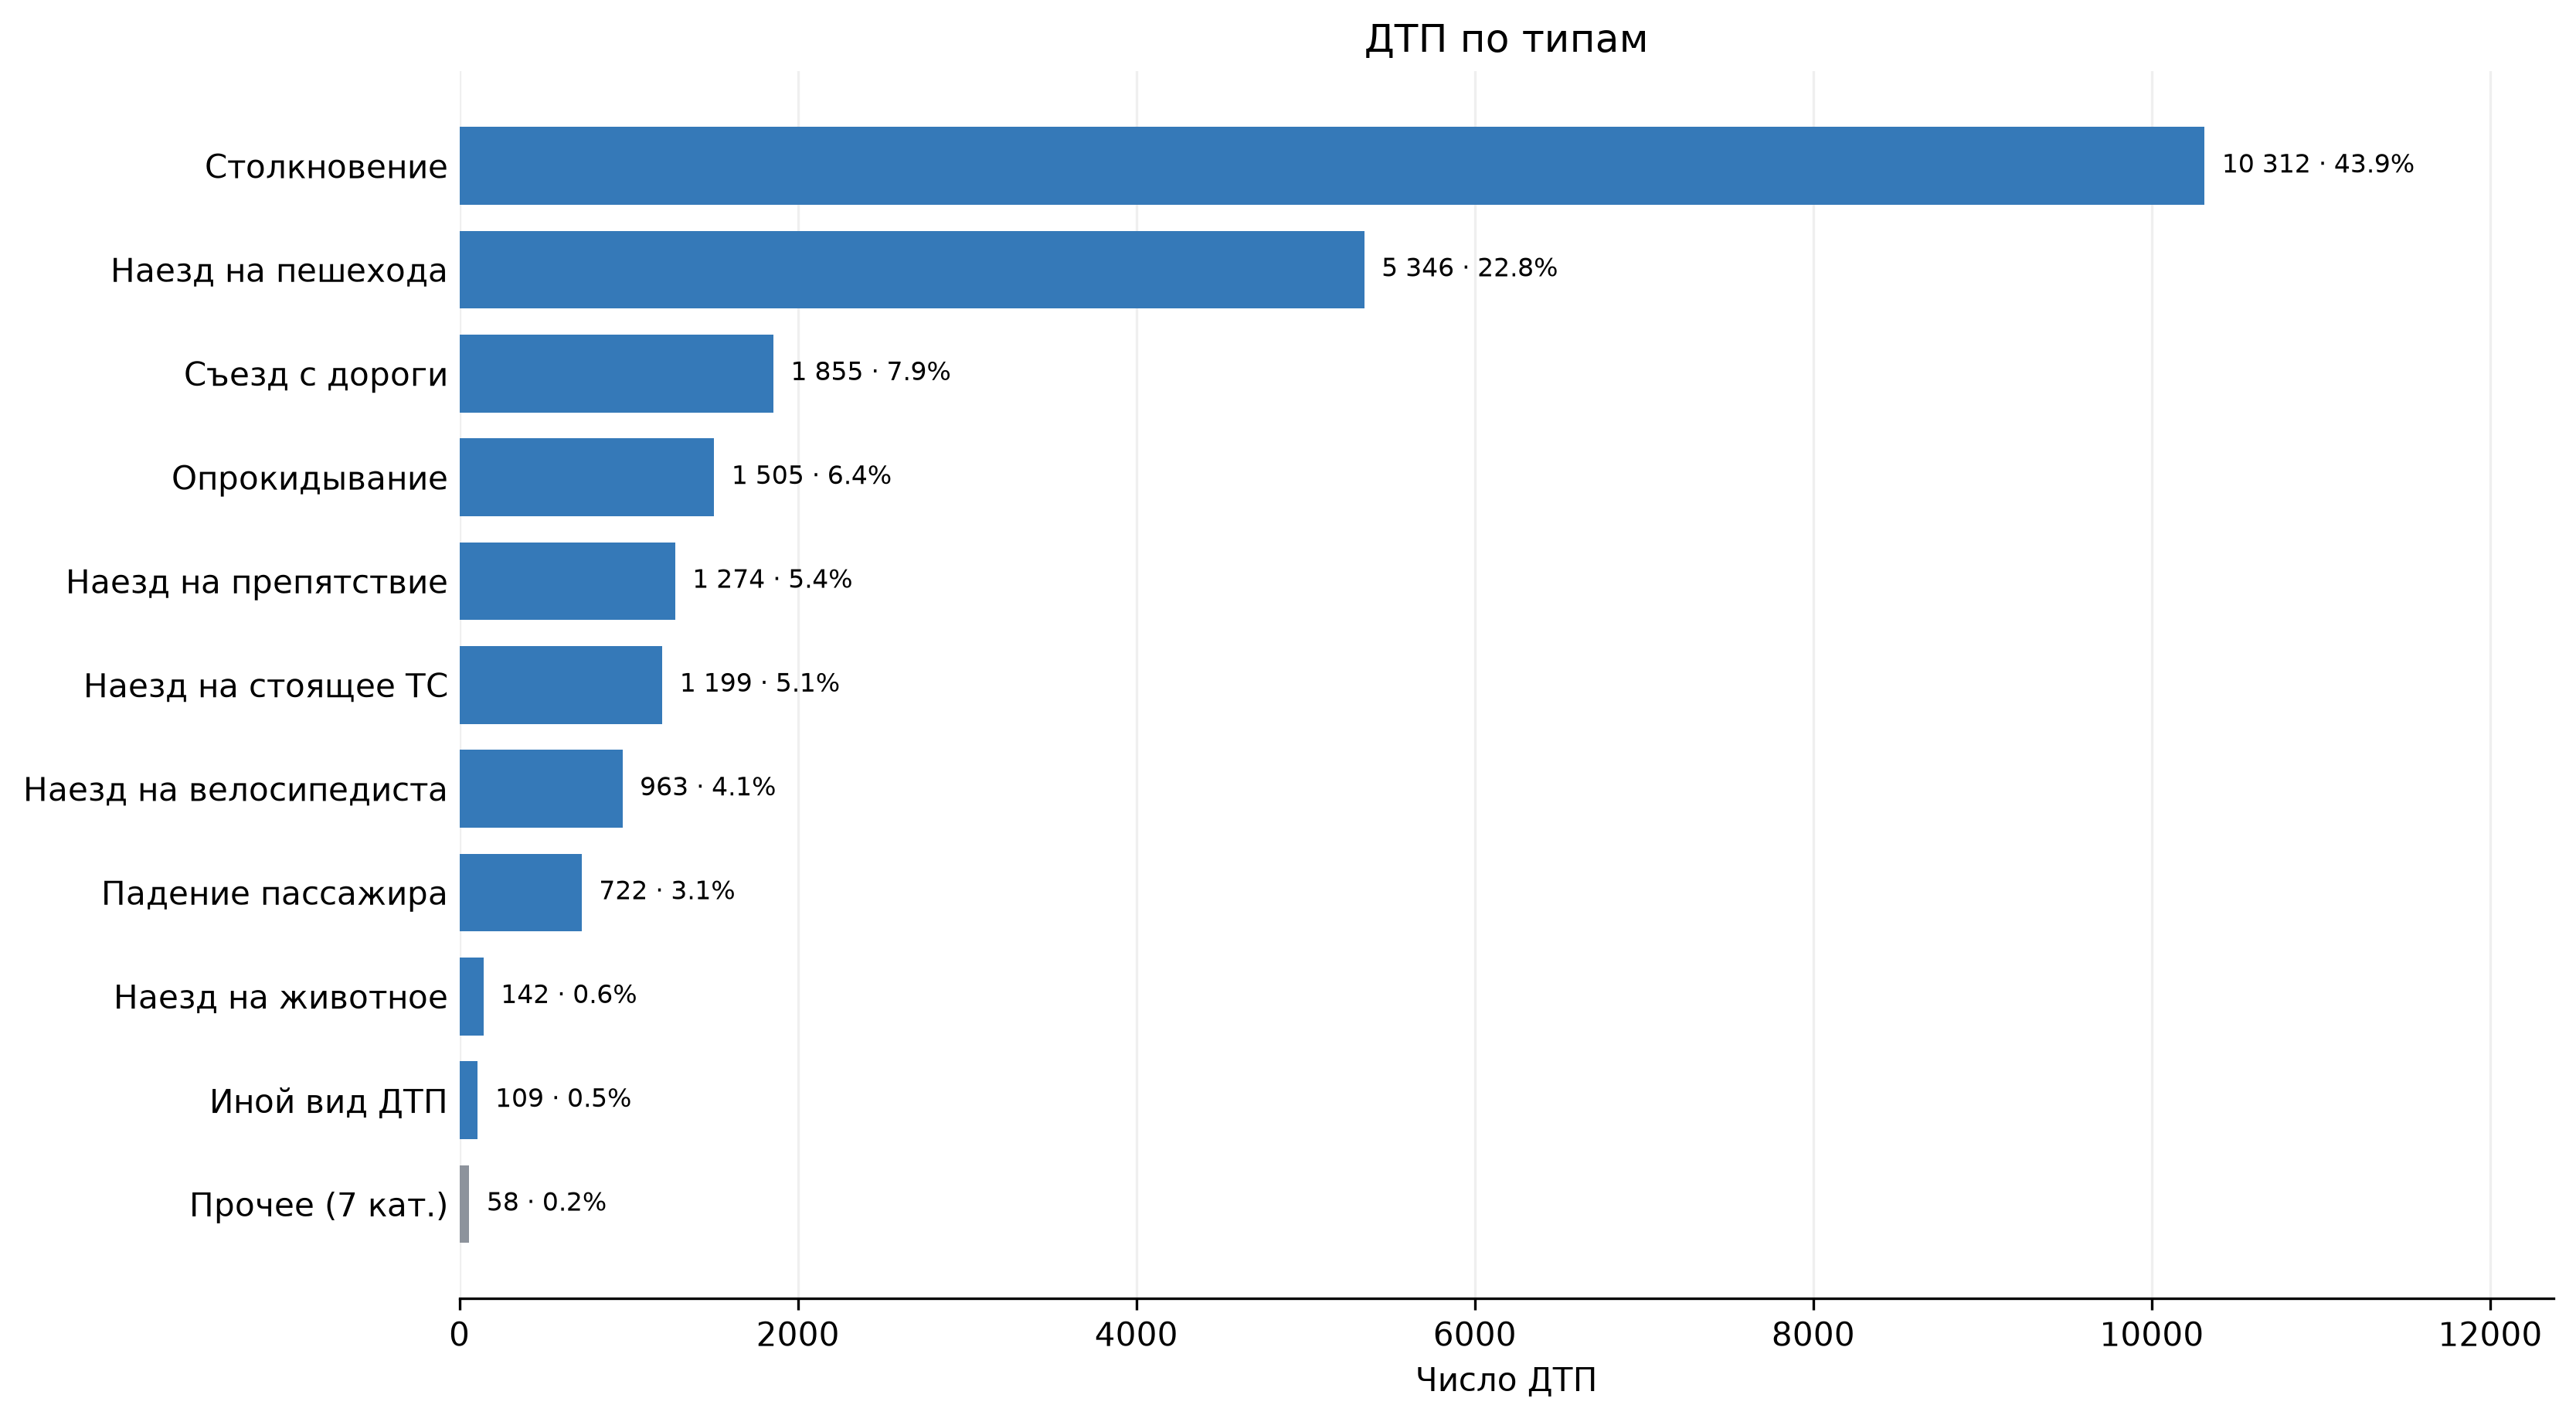

In [4]:
categories = eda.dtp_category_frame(df)
categories = utils.collapse_category_below(categories)
fig, ax = visualize.accidents_by_category_bars(categories)
fig.savefig(FIGURES_MPL / "categories_after.png", dpi=200, facecolor="white")

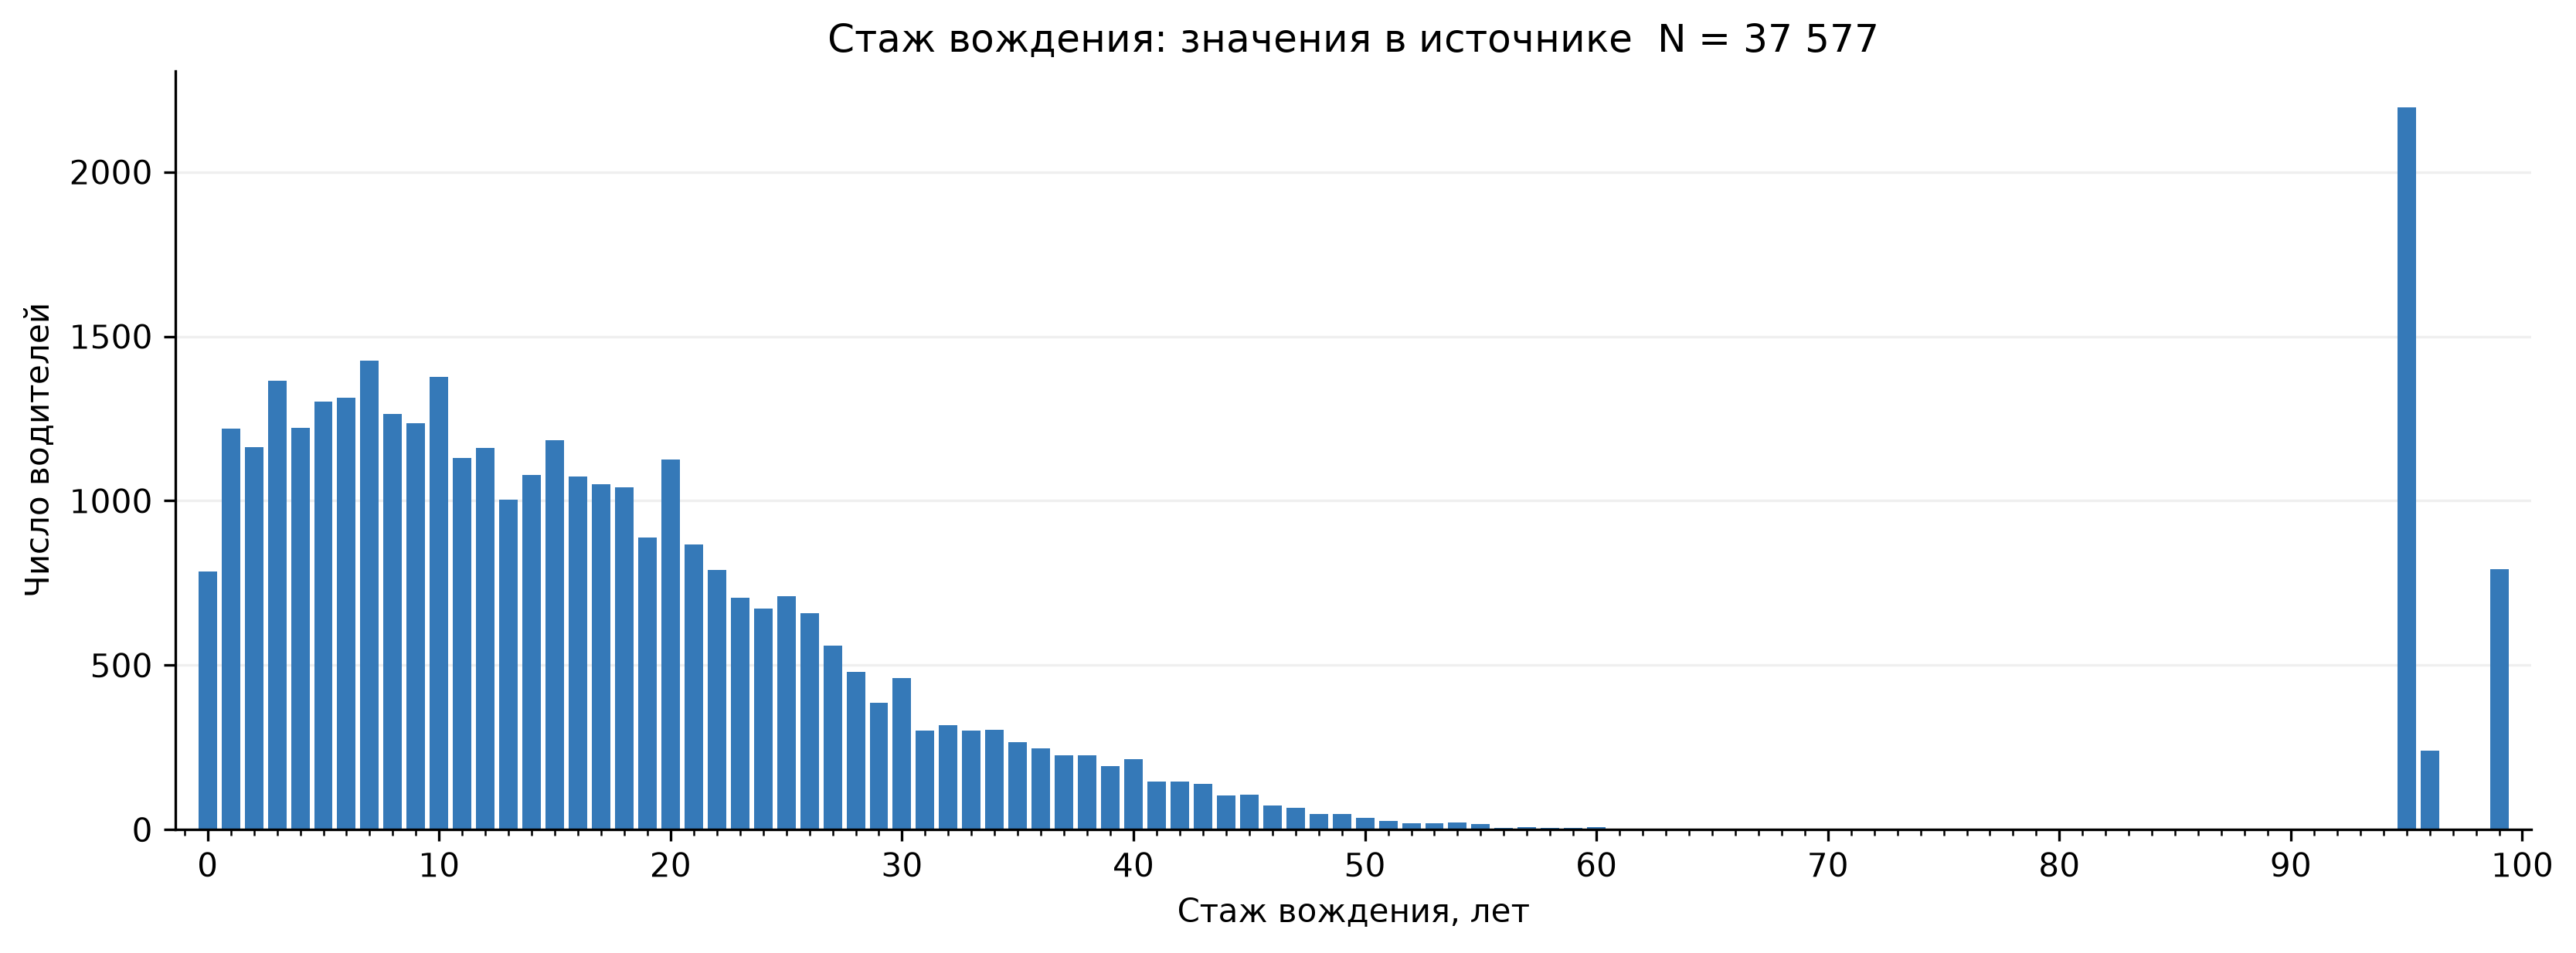

In [5]:
experience = eda.years_of_driving_exp_raw(participants)
fig, ax = visualize.driving_experience_bars(experience)
fig.savefig(FIGURES_MPL / "driving_experience_bars.png", dpi=200, facecolor="white")

## Стаж вождения: ECDF

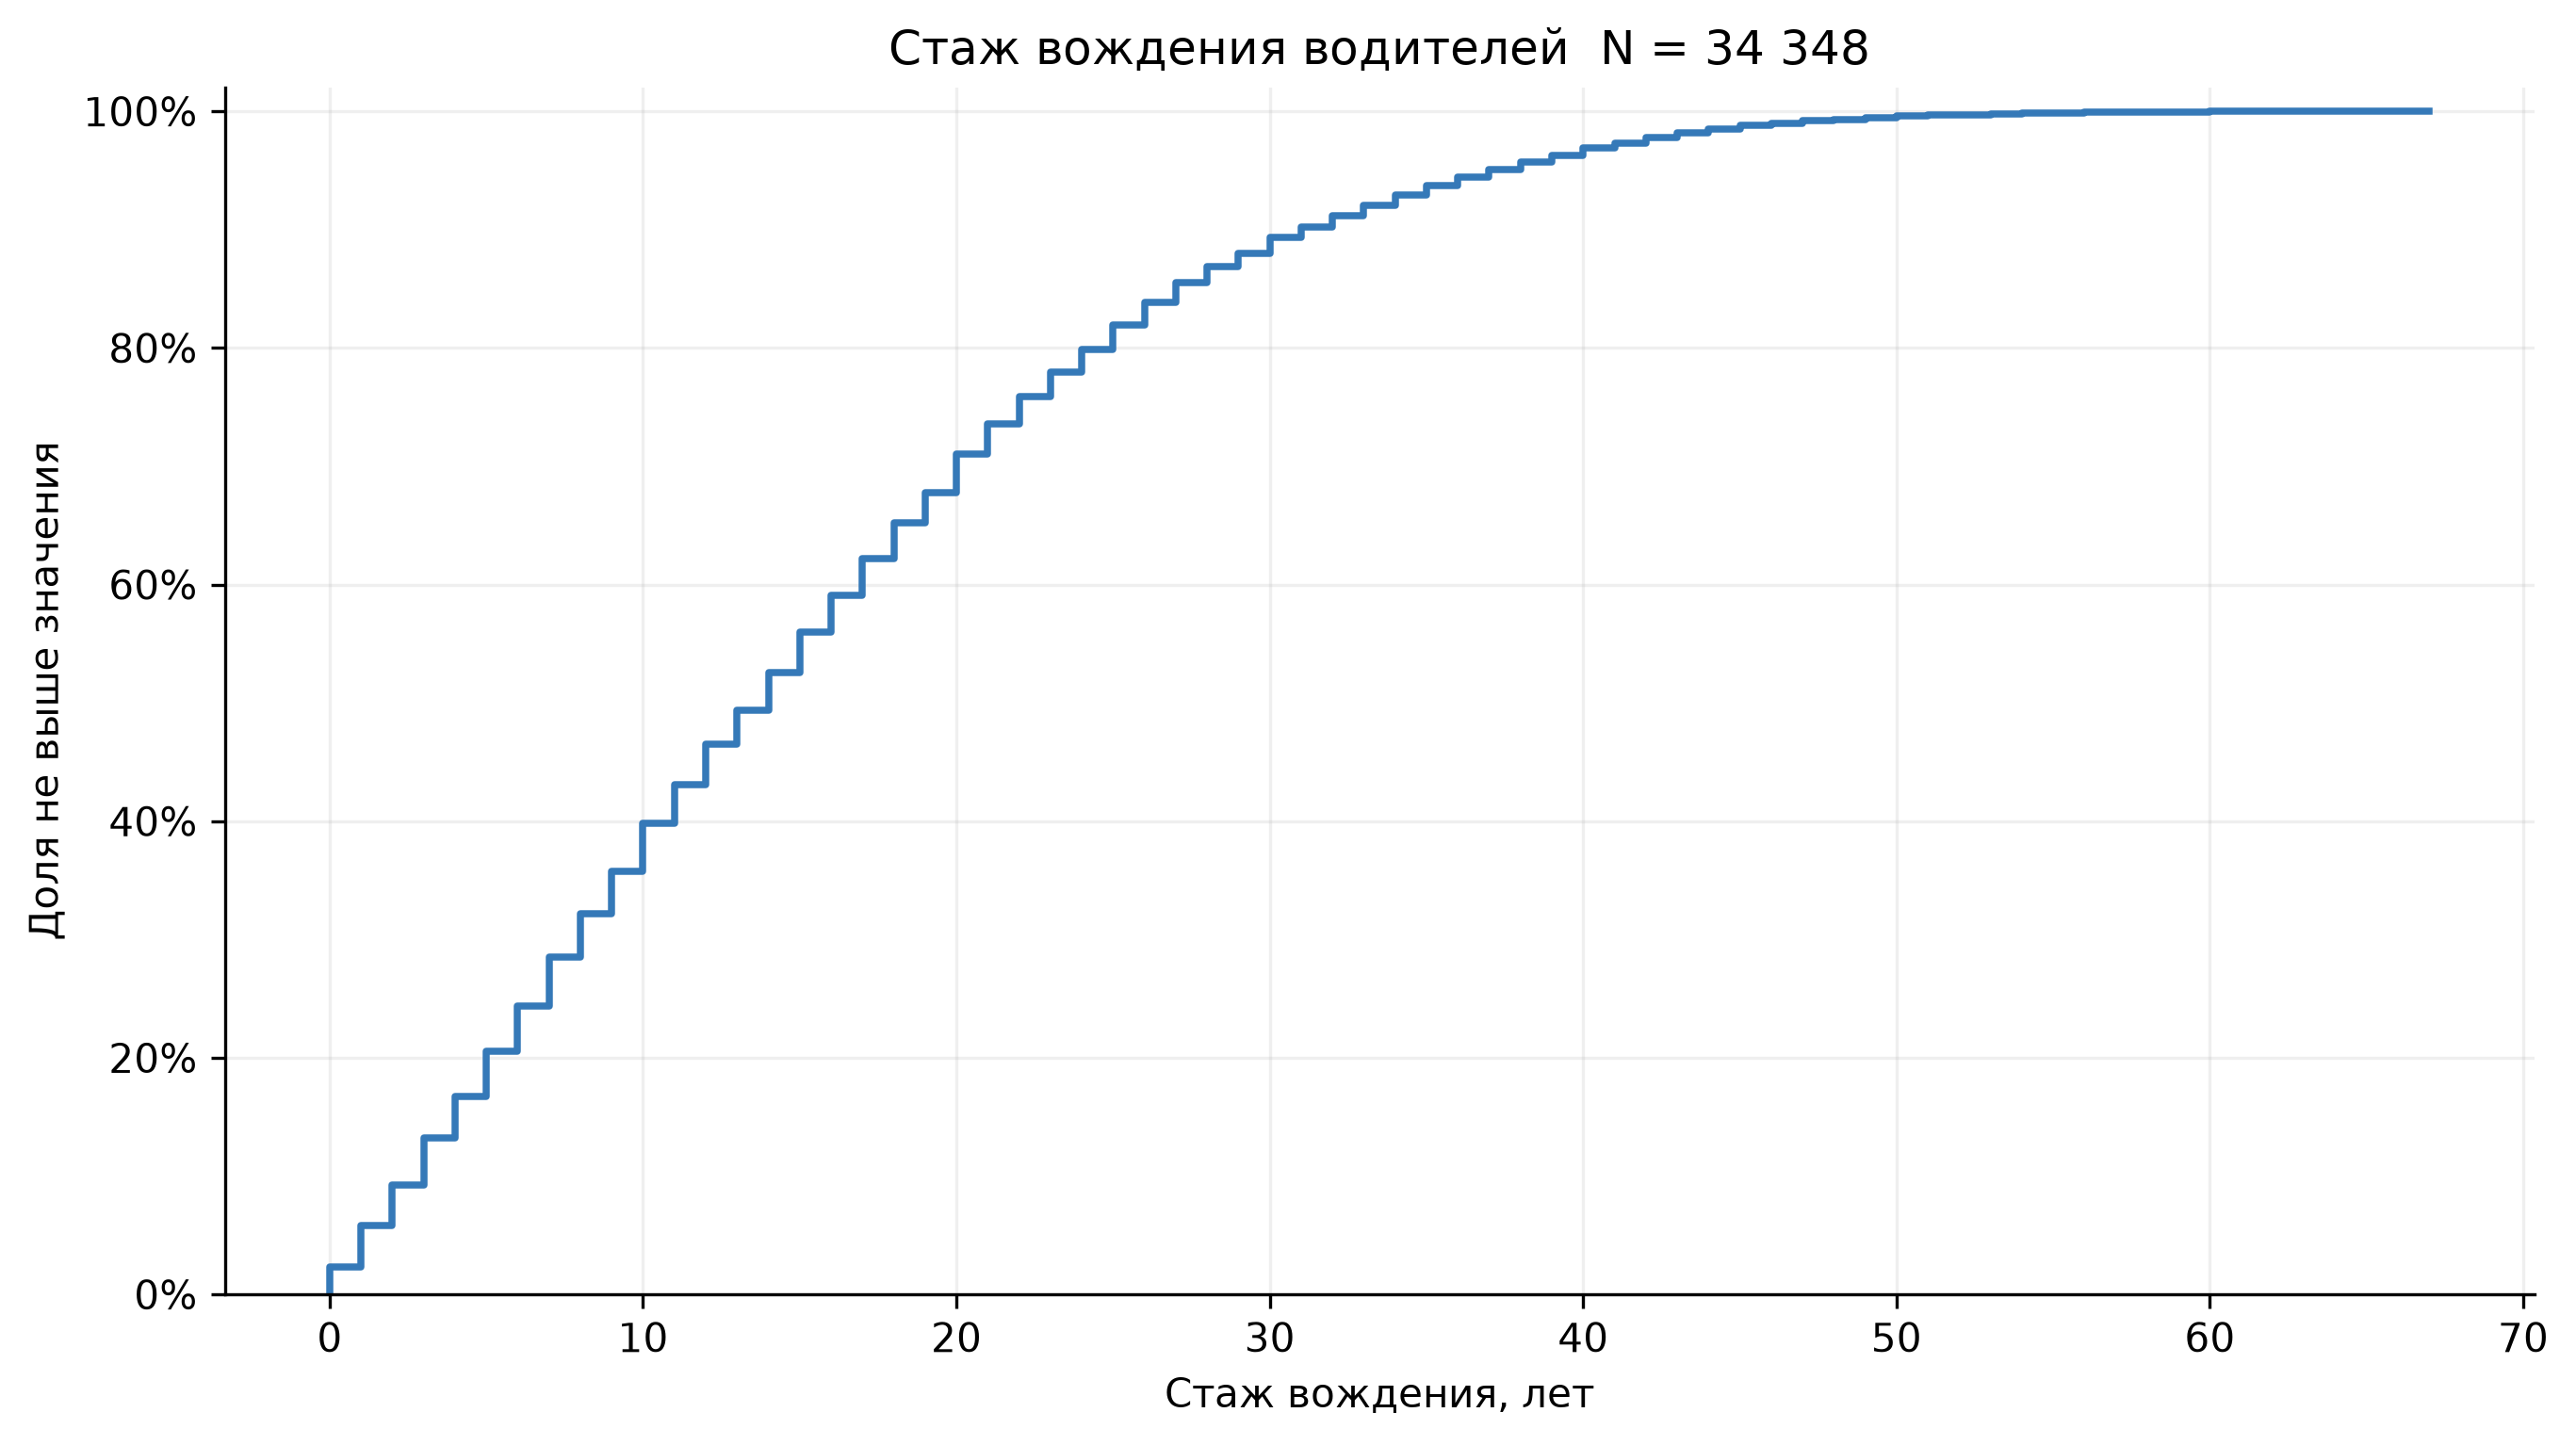

In [6]:
experience = eda.years_of_driving_exp(participants)
fig, ax = visualize.driving_experience_ecdf(experience)
fig.savefig(FIGURES_MPL / "driving_experience_ecdf.png", dpi=200, facecolor="white")

## Связь двух признаков

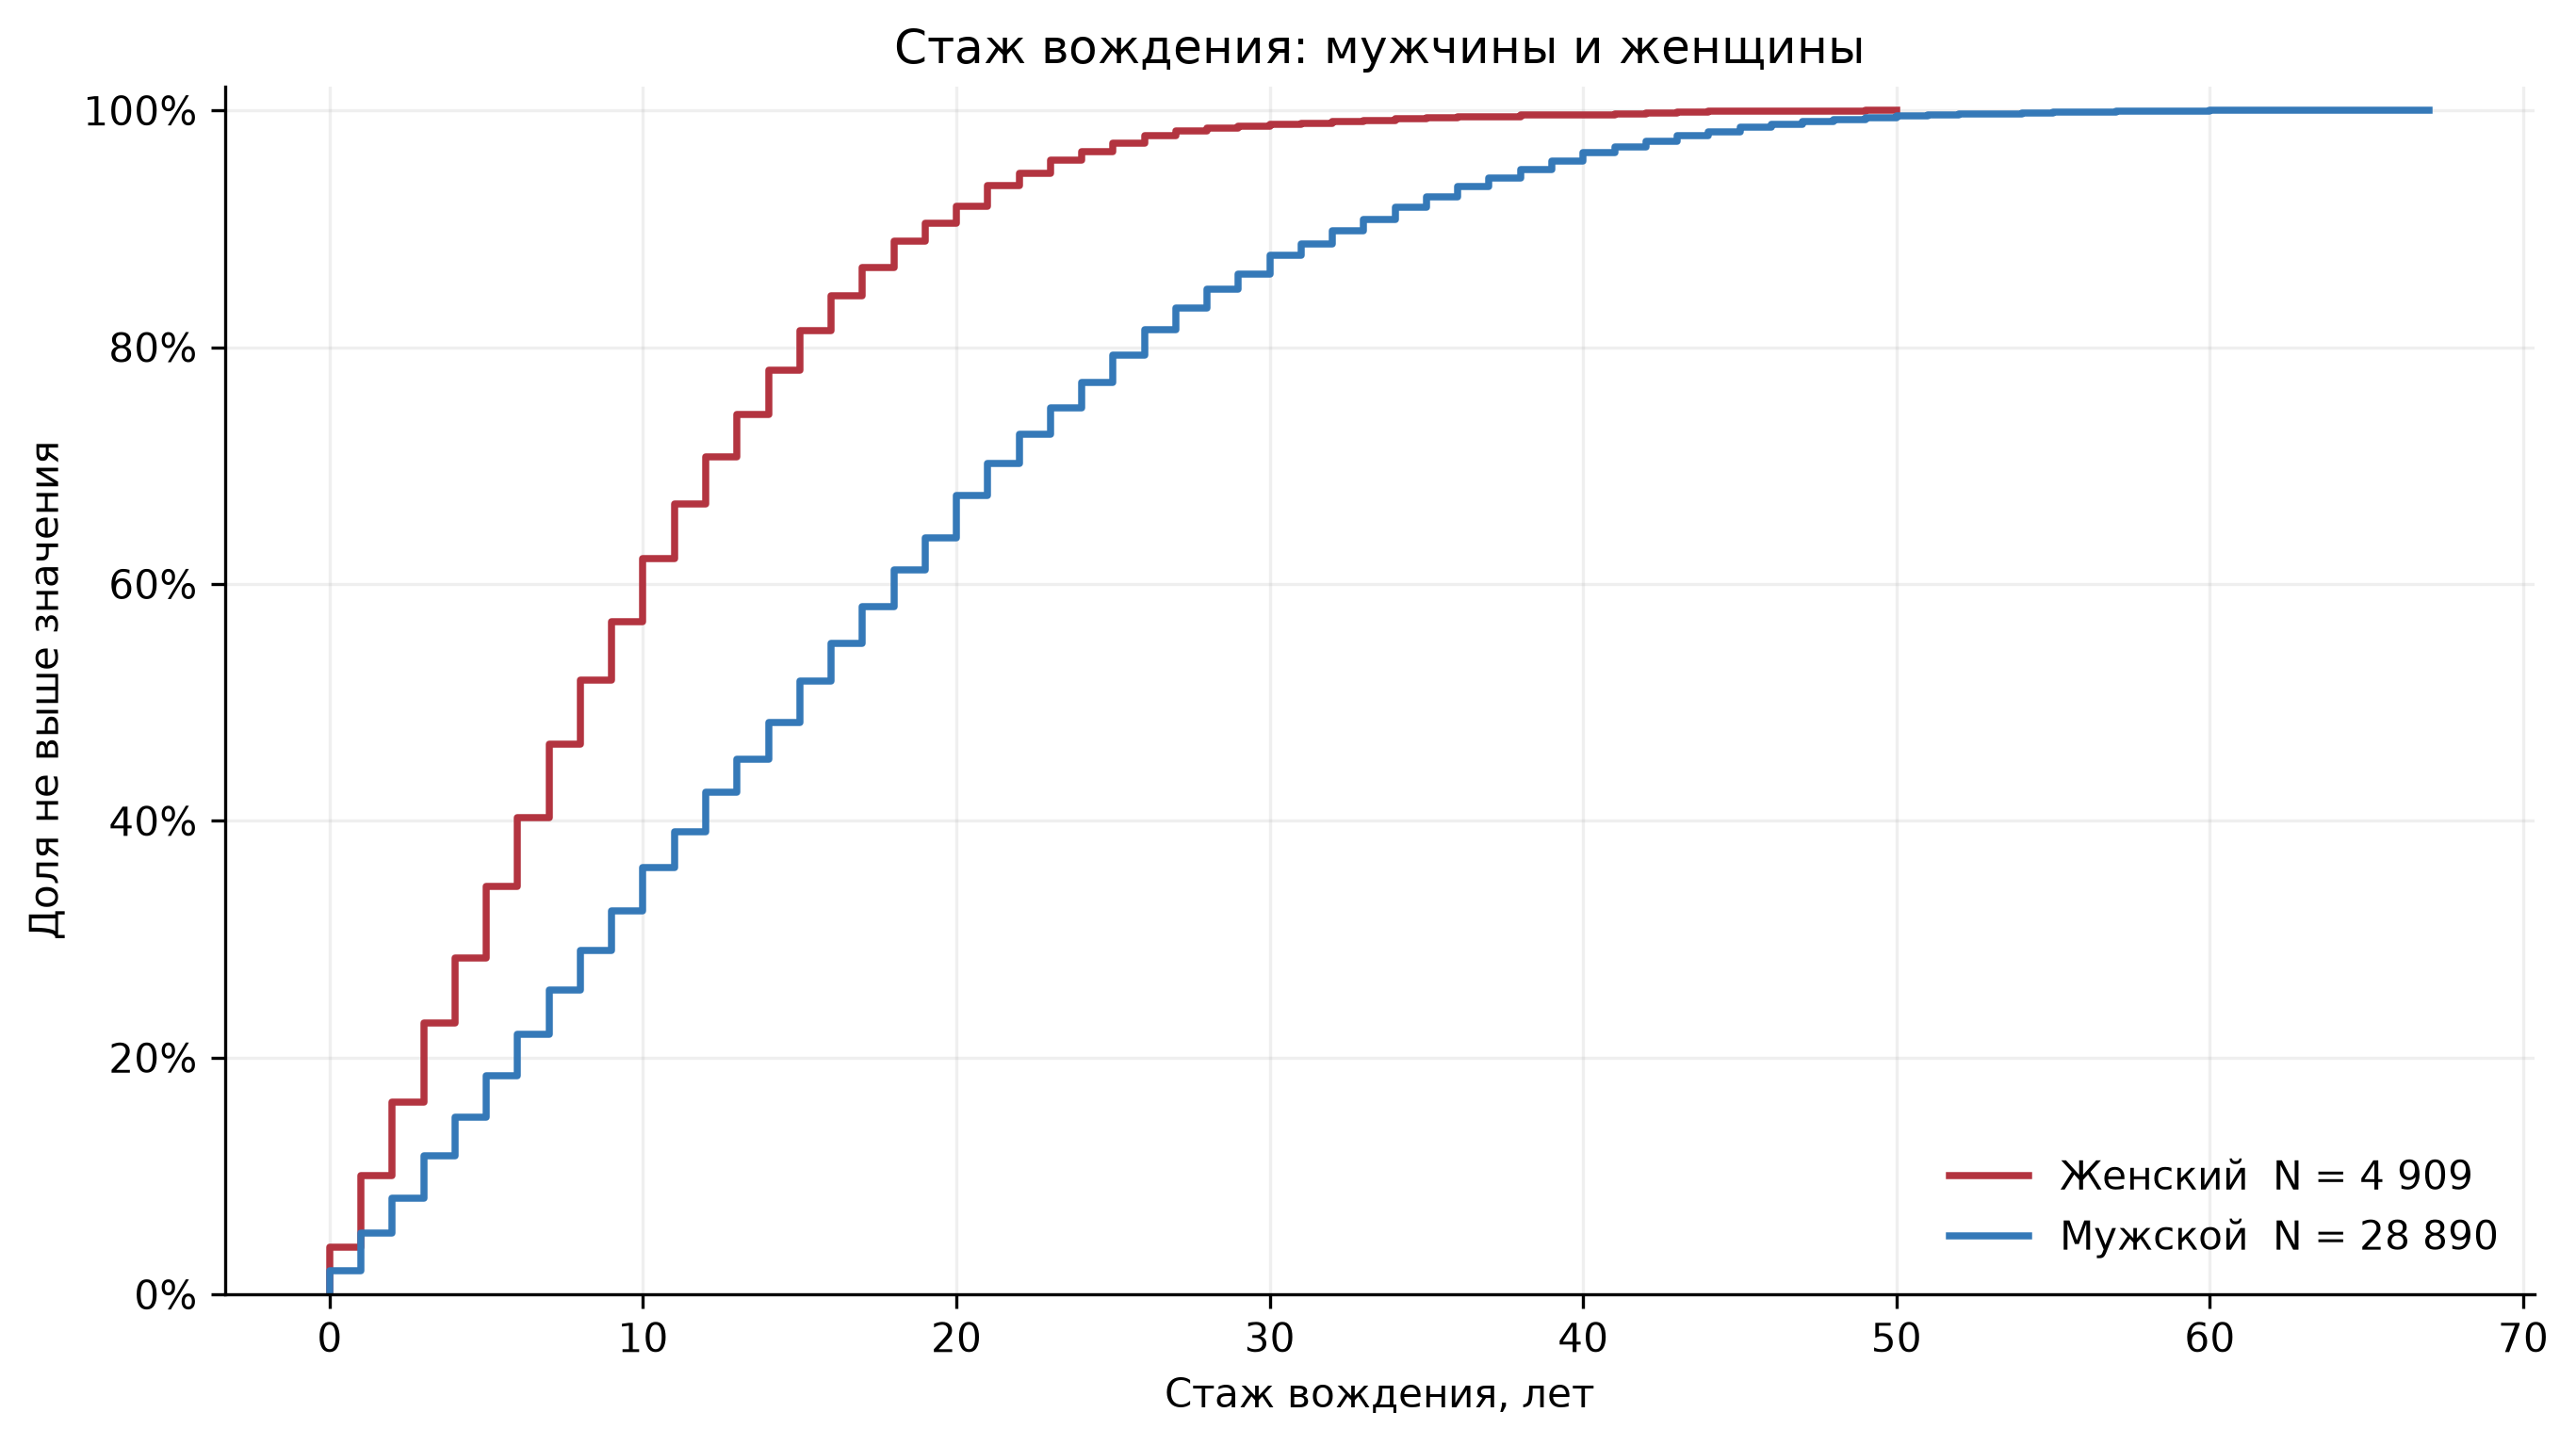

In [7]:
experience = eda.years_of_driving_exp_gender(participants)
fig, ax = visualize.driving_experience_gender_ecdf(experience)
fig.savefig(FIGURES_MPL / "driving_experience_ecdf.png", dpi=200, facecolor="white")

## ДТП: heatmap

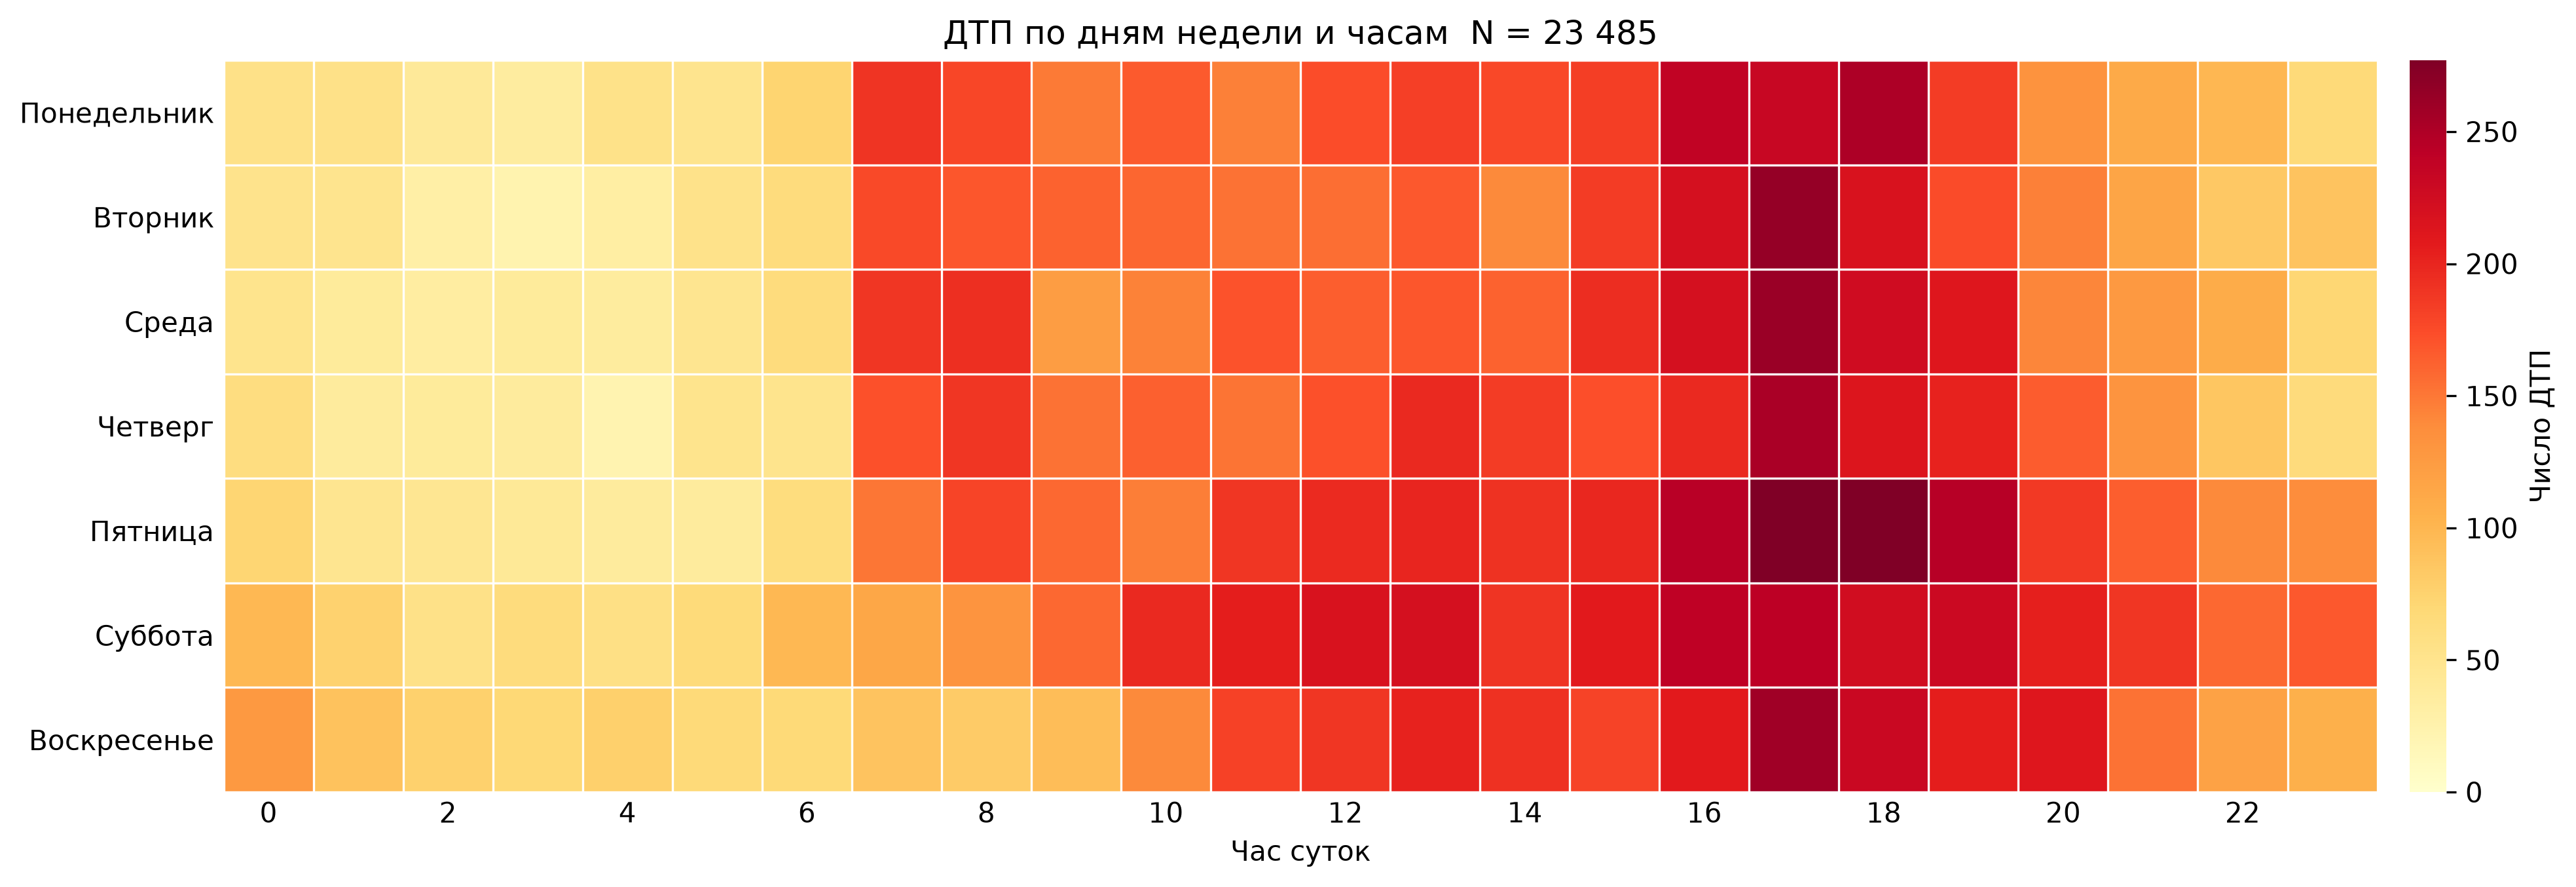

In [8]:
week_day_hour = eda.dtp_week_day_hour_pivot(df)
fig, ax = visualize.accidents_week_day_hour_heatmap(week_day_hour)
fig.savefig(FIGURES_MPL / "accidents_week_day_hour_heatmap.png", dpi=200, facecolor="white")

## Карта: точечная + агрегация

In [9]:
# streamlit

## PCA по профилям территорий


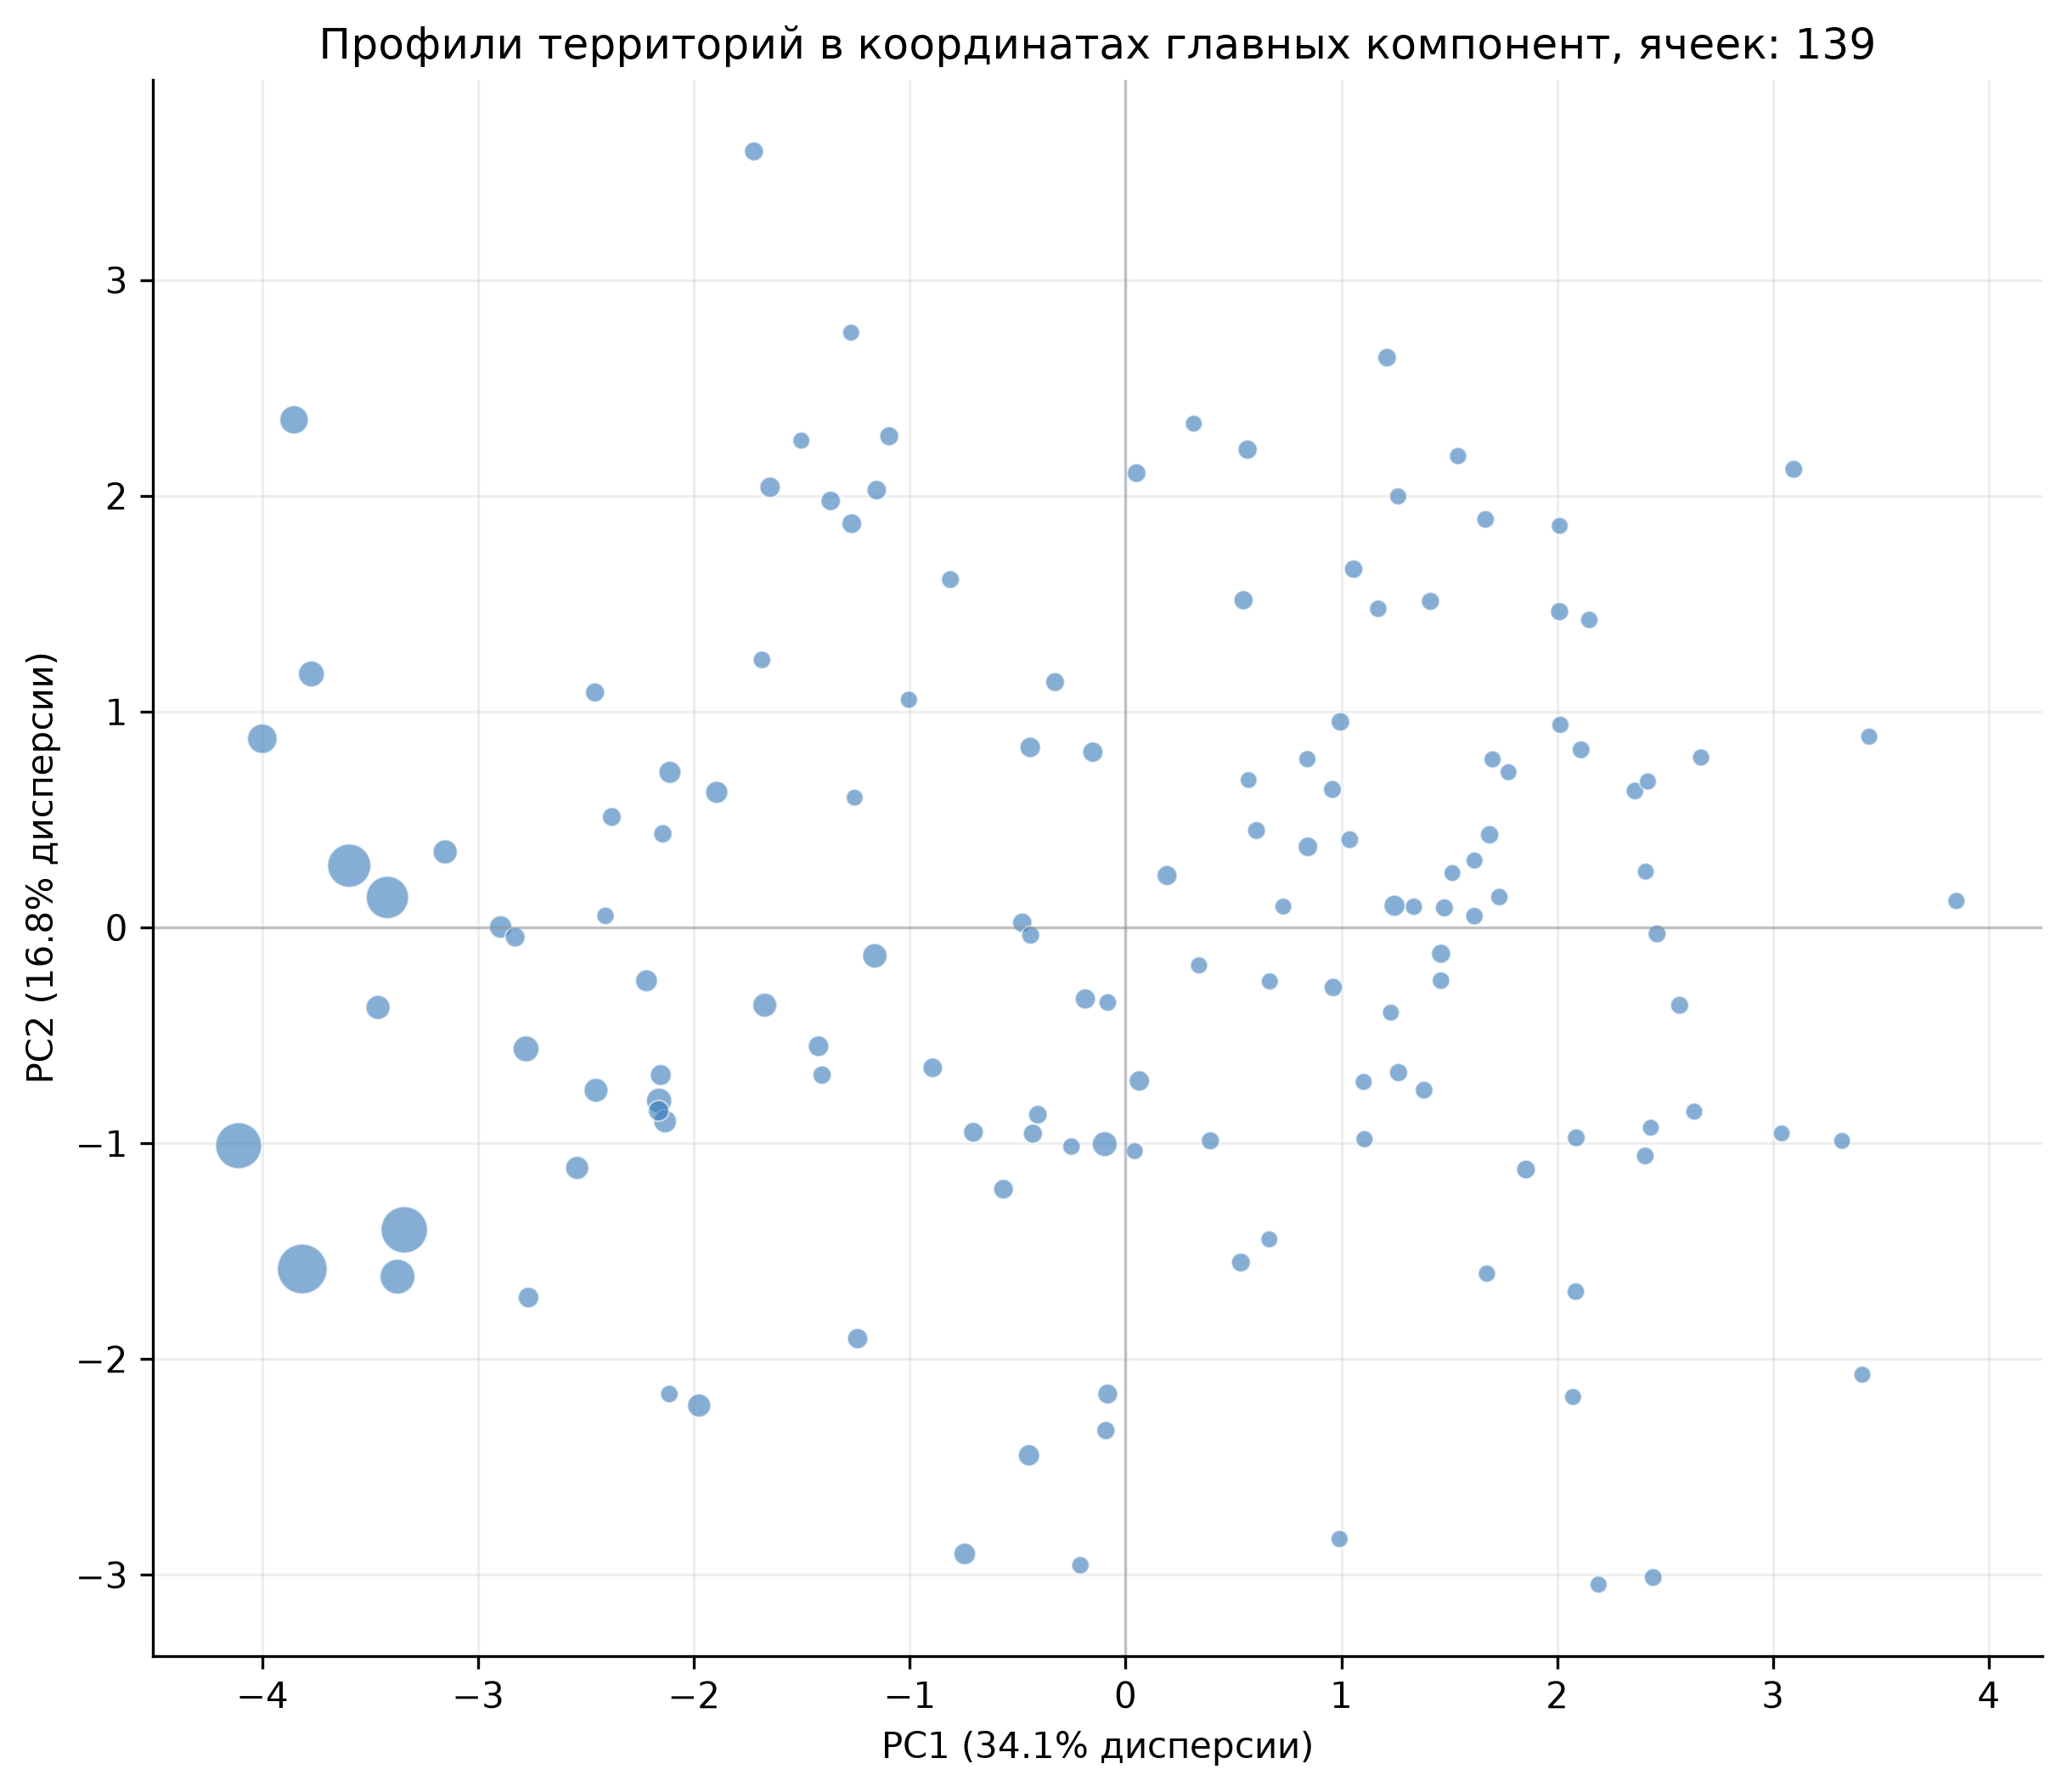

In [10]:
profiles = pca.h3_to_pca(df)
pca_coords, variance, weights = pca.pca(profiles)

fig, ax = visualize.pca_scatter(pca_coords, variance)
fig.savefig(FIGURES_MPL / "pca_scatter.png", dpi=200, facecolor="white")


## t-SNE

## t-SNE: два запуска с разной perplexity


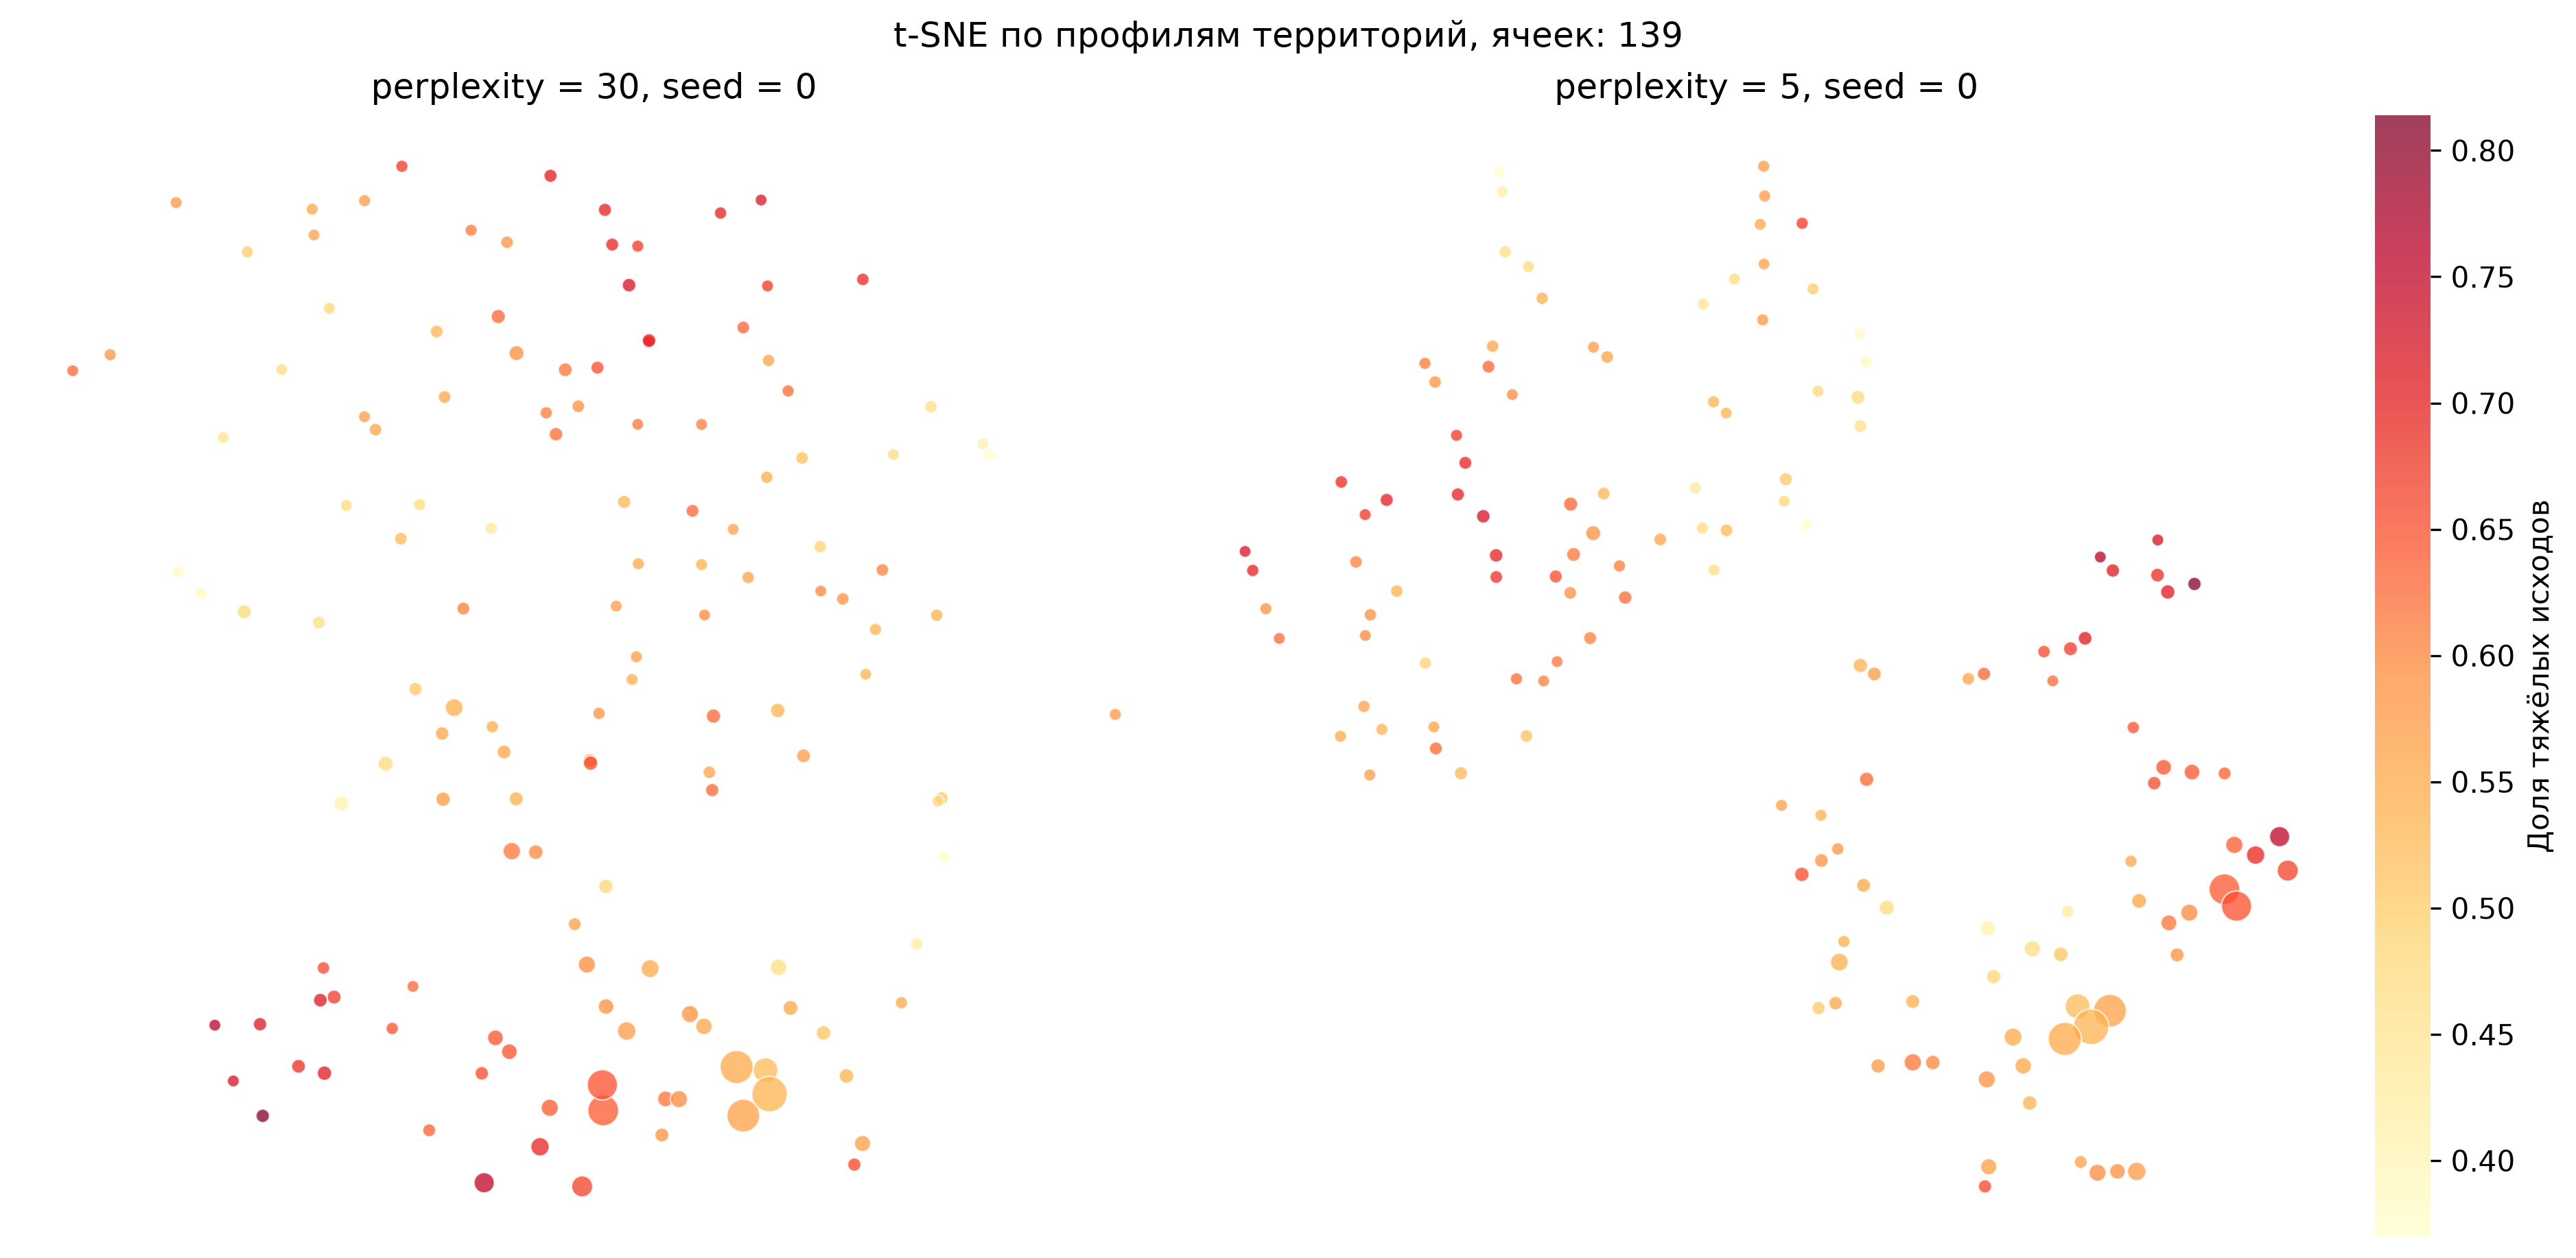

In [11]:
tsne_main = pca.tsne(profiles, perplexity=30, random_state=0)
tsne_alt = pca.tsne(profiles, perplexity=5, random_state=0)
runs = [(tsne_main, "perplexity = 30, seed = 0"), (tsne_alt, "perplexity = 5, seed = 0")]

fig, axes = visualize.tsne_compare(
    runs, color=np.log10(profiles["count"]), color_label="ДТП в ячейке, log10",
)
fig.savefig(FIGURES_MPL / "tsne_count.png", dpi=200, facecolor="white")


In [ ]:
fig, axes = visualize.tsne_compare(
    runs, color=profiles["severity_Тяжёлый"], color_label="Доля тяжёлых исходов",
)
fig.savefig(FIGURES_MPL / "tsne_severity.png", dpi=200, facecolor="white")


## Гипотеза 1: освещение и смертность ночных ДТП


In [ ]:
night = hyp.night_accidents(df)
night_cells = hyp.cell_lighting_table(night, min_each=5)
night_perm = hyp.lighting_permutation(night, night_cells)
night_boot = hyp.lighting_bootstrap(night_cells)
night_ci = (night_boot["ci_lower"], night_boot["ci_upper"])


In [ ]:
fig, ax = visualize.cell_difference_strip(night_cells, night_boot["observed"], night_ci)
fig.savefig(FIGURES_MPL / "lighting_cells.png", dpi=200, facecolor="white")


In [ ]:
fig, ax = visualize.permutation_null(
    night_perm["null"], night_perm["observed"], night_perm["p_value"],
)
fig.savefig(FIGURES_MPL / "lighting_permutation.png", dpi=200, facecolor="white")


In [ ]:
raw_gap = night.groupby("lit")["fatal"].mean()
naive = float(raw_gap[False] - raw_gap[True])

fig, ax = visualize.effect_comparison([
    ("Без контроля территории", naive, (naive, naive)),
    ("Внутри ячеек H3", night_boot["observed"], night_ci),
])
fig.savefig(FIGURES_MPL / "lighting_effect.png", dpi=200, facecolor="white")


## Гипотеза 2: смертность в ВАЗ


In [ ]:
occupants = brands.occupants_frame(df)
mixed = brands.mixed_brand_occupants(df)
brand_perm = brands.brand_permutation(mixed)


In [ ]:
fig, ax = visualize.brand_mortality_bars(brands.brand_mortality_ci(occupants))
fig.savefig(FIGURES_MPL / "brand_mortality.png", dpi=200, facecolor="white")


In [ ]:
fig, ax = visualize.permutation_null(
    brand_perm["null"], brand_perm["observed"], brand_perm["p_value"],
    xlabel="Средняя по ДТП разница долей погибших, п.п.",
    title="ВАЗ против других марок внутри одного ДТП",
)
fig.savefig(FIGURES_MPL / "brand_permutation.png", dpi=200, facecolor="white")


## Гипотеза 3: стаж водителя и вероятность пострадать


In [ ]:
drivers = hyp.driver_outcomes(df)


# Графики дашборда

Те же фигуры, что показывает `app.py`: строятся через `charts.py` и сохраняются в `figures/` с префиксом `app_`.

In [ ]:
import charts
import geo

app_df = data_loading.full_frame_to_app(df)


def save(fig, name, width=1300, height=None):
    fig.write_image(
        FIGURES_PLOTLY / f"{name}.png",
        width=width, height=height or fig.layout.height or 520, scale=2,
    )
    return fig

## Динамика

In [ ]:
save(charts.month_line(eda.dtp_year_month_frame(app_df)), "month_line")

In [ ]:
save(charts.week_day_hour_heatmap(eda.dtp_week_day_hour_pivot(app_df)), "week_hour_heatmap")

## Структура

In [ ]:
app_categories = eda.dtp_category_frame(app_df)

save(charts.category_bars_draft(app_categories), "categories_before", height=700)
save(charts.category_bars(utils.collapse_category_below(app_categories)), "categories_after")

In [ ]:
save(charts.severity_by_light(eda.severity_by_light_frame(app_df)), "severity_by_light")

In [ ]:
app_experience = eda.years_of_driving_exp_gender(participants)

save(
    charts.experience_ecdf(
        app_experience, group="gender", medians=eda.experience_medians(app_experience)
    ),
    "experience_ecdf",
)

## Карта

В приложении подложка `open-street-map`; для экспорта в PNG используется `carto-positron` — растровые тайлы OSM kaleido не отрисовывает.

In [ ]:
MAP_STYLE = "carto-positron"

map_points = app_df[geo.region_mask(app_df)]
map_center = {
    "lat": float(map_points["latitude"].median()),
    "lon": float(map_points["longitude"].median()),
}
map_zoom = geo.zoom_for(map_points)

map_sample = map_points.sample(5000, random_state=42)
map_sample = map_sample.assign(
    severity_display=map_sample["severity"].fillna("〈значение отсутствует〉")
)

save(charts.point_map(map_sample, map_center, MAP_STYLE, map_zoom), "point_map", height=540)

In [ ]:
hex_cells = geo.hex_counts(geo.cell_ids(map_points, 7))

save(
    charts.hex_map(hex_cells, geo.hex_geojson(hex_cells["cell"]), map_center, MAP_STYLE, map_zoom),
    "hex_map", height=540,
)

## Проекции

In [ ]:
save(
    charts.projection_scatter(
        pca_coords, "pc1", "pc2",
        title="PCA: профили территорий",
        x_label=f"PC1 ({variance[0]:.1%} дисперсии)",
        y_label=f"PC2 ({variance[1]:.1%} дисперсии)",
    ),
    "pca",
)

In [ ]:
tsne_colour = np.log10(profiles["count"])

save(
    charts.projection_scatter(
        tsne_main, "tsne1", "tsne2", title="t-SNE · perplexity = 30, seed = 0",
        color=tsne_colour, color_label="ДТП, log10",
    ),
    "tsne_main", width=900,
)
save(
    charts.projection_scatter(
        tsne_alt, "tsne1", "tsne2", title="t-SNE · perplexity = 5, seed = 0",
        color=tsne_colour, color_label="ДТП, log10",
    ),
    "tsne_alt", width=900,
)

## Гипотезы

In [ ]:
save(charts.cell_difference_strip(night_cells, night_boot["observed"], night_ci), "lighting_cells")

In [ ]:
save(charts.brand_mortality_dots(brands.brand_mortality_ci(occupants)), "brand_mortality")

In [ ]:
save(charts.experience_outcome(hyp.experience_table_ci(drivers)), "experience_outcome")